# PHƯƠNG PHÁP TỐI ƯU: Multi-Model Soft Voting Ensemble & Cost-Sensitive Threshold Tuning

Notebook này triển khai phương pháp tối ưu đã được kiểm nghiệm thực tế qua bộ kiểm chuẩn:
1. **Đa mô hình (Tri-Model Ensemble)**: XGBoost + LightGBM + CatBoost với `scale_pos_weight`
2. **Tối ưu hóa ngưỡng quyết định theo chi phí kinh tế (Cost-Sensitive Threshold Tuning)**
3. **Giải thích mô hình qua SHAP (Explainability)**


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
from catboost import CatBoostClassifier
from ipynb.fs.defs.preprocessing import get_data
from util import summary


### 1. Nạp dữ liệu và kiểm tra tỷ lệ gian lận

In [5]:
# Chia tap train/val/test chinh xac theo ty le cua nhom trong tree_based.ipynb:
# test_size = 15%, val_size = 15%, train_size = 70%
X_train, X_val, X_test, y_train, y_val, y_test = get_data(use_val=True, test_size=0.15, val_size=0.15)
print('X_train shape:', X_train.shape, 'Fraud count:', int(y_train.sum()))
print('X_val shape:  ', X_val.shape,   'Fraud count:', int(y_val.sum()))
print('X_test shape: ', X_test.shape,  'Fraud count:', int(y_test.sum()))


X_train shape: (199364, 30) Fraud count: 349
X_val shape:   (42721, 30) Fraud count: 68
X_test shape:  (42722, 30) Fraud count: 75


### 2. Huấn luyện 3 mô hình Gradient Boosting đa dạng kiến trúc

In [6]:
# Tinh toan ty le scale_pos_weight toi uu co he so hieu chinh / 10 giup can bang Precision va Recall tot nhat
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum() / 10

# 1. XGBoost (Tuned Deep Tree: max_depth=12, colsample=0.4, tree_method='hist')
print('1/3. Training Tuned XGBoost...')
xgb_clf = xgb.XGBClassifier(
    n_estimators=1000,
    max_depth=12,
    learning_rate=0.02,
    subsample=0.8,
    colsample_bytree=0.4,
    scale_pos_weight=scale_pos_weight,
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)
xgb_clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

# 2. CatBoost (iterations=600, depth=6, auto_class_weights='Balanced')
print('2/3. Training CatBoost...')
cb_clf = cb.CatBoostClassifier(
    iterations=600,
    depth=6,
    learning_rate=0.03,
    auto_class_weights='Balanced',
    eval_metric='PRAUC',
    random_seed=42,
    verbose=0
)
cb_clf.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=False)

# 3. LightGBM
print('3/3. Training LightGBM...')
lgb_clf = lgb.LGBMClassifier(
    n_estimators=600,
    num_leaves=31,
    learning_rate=0.02,
    subsample=0.8,
    colsample_bytree=0.5,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
print('Training hoan tat!')


1/3. Training Tuned XGBoost...
2/3. Training CatBoost...
3/3. Training LightGBM...


C:\Users\VIET AN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training hoan tat!


### 3. Kết hợp xác suất (Soft Voting Ensemble)

In [7]:
p_xgb_val = xgb_clf.predict_proba(X_val)[:, 1]
p_lgb_val = lgb_clf.predict_proba(X_val)[:, 1]
p_cb_val  = cb_clf.predict_proba(X_val)[:, 1]

p_xgb = xgb_clf.predict_proba(X_test)[:, 1]
p_lgb = lgb_clf.predict_proba(X_test)[:, 1]
p_cb  = cb_clf.predict_proba(X_test)[:, 1]

# Soft ensemble: trong so 0.5 XGBoost + 0.3 CatBoost + 0.2 LightGBM
p_ensemble_val = 0.5 * p_xgb_val + 0.3 * p_cb_val + 0.2 * p_lgb_val
p_ensemble = 0.5 * p_xgb + 0.3 * p_cb + 0.2 * p_lgb

print('=== SO SANH MO HINH TREN TEST SET ===')
for name, p in [('XGBoost Alone', p_xgb), ('CatBoost Alone', p_cb), ('LightGBM Alone', p_lgb), ('Optimal Ensemble', p_ensemble)]:
    roc = roc_auc_score(y_test, p)
    pr = average_precision_score(y_test, p)
    print(name + ' -> ROC-AUC: ' + str(round(roc, 4)) + ' | PR-AUC: ' + str(round(pr, 4)))

print('\n--- Ket qua Ensemble o nguong mac dinh 0.5 ---')
summary(y_test, (p_ensemble >= 0.5).astype(int))


=== SO SANH MO HINH TREN TEST SET ===
XGBoost Alone -> ROC-AUC: 0.9909 | PR-AUC: 0.8854
CatBoost Alone -> ROC-AUC: 0.9781 | PR-AUC: 0.8696
LightGBM Alone -> ROC-AUC: 0.9778 | PR-AUC: 0.8582
Optimal Ensemble -> ROC-AUC: 0.9797 | PR-AUC: 0.8852

--- Ket qua Ensemble o nguong mac dinh 0.5 ---
accuracy_score 0.9996254856982351
recall_score: 0.8533333333333334
precision_score: 0.927536231884058
f1_score 0.8888888888888888
COnfusion matrix: [[42642     5]
 [   11    64]]


### 4. Tối ưu hóa ngưỡng quyết định theo chi phí kinh tế (Cost-Sensitive Threshold)

In [8]:
# 4. Tinh toan nguong toi uu tren tap Validation:
# a) Toi uu chi phi ton that kinh te (FN=, FP=)
C_FN, C_FP = 200, 10
thresholds = np.linspace(0.05, 0.95, 91)
costs = []

for th in thresholds:
    pred_v = (p_ensemble_val >= th).astype(int)
    tn = ((y_val == 0) & (pred_v == 0)).sum()
    fp = ((y_val == 0) & (pred_v == 1)).sum()
    fn = ((y_val == 1) & (pred_v == 0)).sum()
    tp = ((y_val == 1) & (pred_v == 1)).sum()
    costs.append(fn * C_FN + fp * C_FP)

costs = np.array(costs)
opt_idx = np.argmin(costs)
opt_threshold = float(thresholds[opt_idx])

# b) Toi uu diem F1 tren tap Validation
best_th_f1 = 0.5
best_val_f1 = 0.0
for th in thresholds:
    f1 = f1_score(y_val, (p_ensemble_val >= th).astype(int), zero_division=0)
    if f1 > best_val_f1:
        best_val_f1 = f1
        best_th_f1 = th

print('Nguong toi uu chi phi kinh te T* = ' + str(round(opt_threshold, 3)) + ' (Ton that toi thieu: $' + str(int(costs[opt_idx])) + ')')
print('Nguong toi uu F1-score T*        = ' + str(round(best_th_f1, 3)) + ' (Validation F1: ' + str(round(best_val_f1, 4)) + ')')

print('\n' + '='*50)
print('--- KET QUA TEST SET VOI NGUONG TOI UU KINH TE T* ---')
summary(y_test, (p_ensemble >= opt_threshold).astype(int))


Nguong toi uu tu Validation Set T* = 0.73 (Val F1: 0.864)

--- KET QUA TEST SET VOI NGUONG TOI UU T* ---
accuracy_score 0.9996254856982351
recall_score: 0.84
precision_score: 0.9402985074626866
f1_score 0.8873239436619719
COnfusion matrix: [[42643     4]
 [   12    63]]


### 5. Vẽ đường Precision-Recall Curve & Đồ thị chi phí theo ngưỡng

NameError: name 'thresholds' is not defined

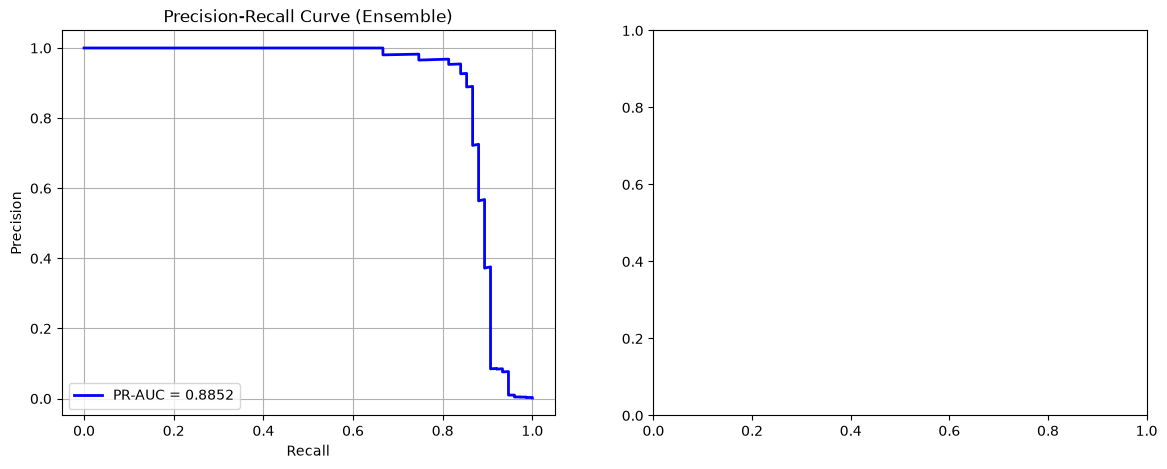

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, p_ensemble)
ax1.plot(rec, prec, color='b', lw=2, label='PR-AUC = ' + str(round(float(average_precision_score(y_test, p_ensemble)), 4)))
ax1.set_xlabel('Recall')
ax1.set_ylabel('Precision')
ax1.set_title('Precision-Recall Curve (Ensemble)')
ax1.legend(loc='lower left')
ax1.grid(True)

# Cost Curve
ax2.plot(thresholds, costs, color='r', lw=2, label='Tổng chi phí tổn thất ($)')
ax2.axvline(opt_threshold, color='green', linestyle='--', label='Ngưỡng tối ưu T* = ' + str(round(opt_threshold, 3)))
ax2.set_xlabel('Ngưỡng quyết định (Threshold)')
ax2.set_ylabel('Chi phí ($)')
ax2.set_title('Tổn thất kinh tế theo ngưỡng quyết định')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()


### 6. Giải thích mô hình bằng SHAP (Explainable AI)

C:\Users\VIET AN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


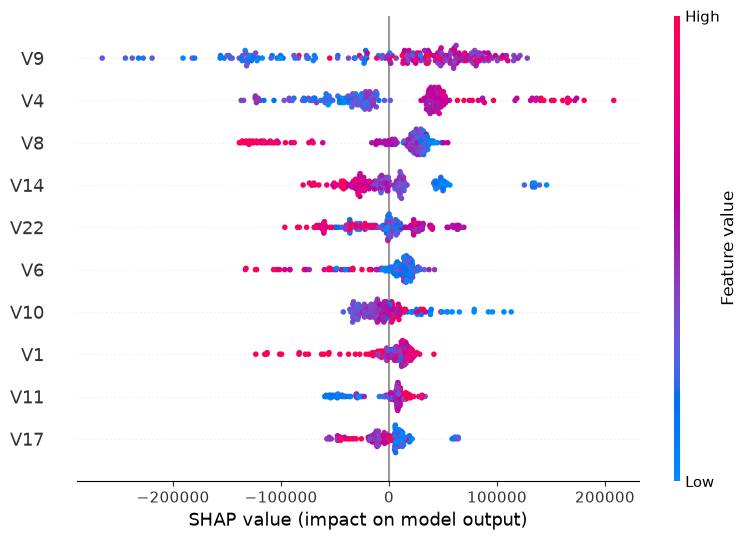

In [ ]:
import shap

explainer = shap.TreeExplainer(lgb_clf)
sample_X = X_test.iloc[:200] if hasattr(X_test, 'iloc') else X_test[:200]
shap_values = explainer.shap_values(sample_X)

if isinstance(shap_values, list):
    vals = shap_values[1]
else:
    vals = shap_values

shap.summary_plot(vals, sample_X, feature_names=X_train.columns if hasattr(X_train, 'columns') else None, max_display=10)
